# Feature #4: Ask Spendif intent classifier

Goal: read a question like `how much did i spend from aug 4 to aug 11` and predict its **intent** (`spend_total`).
Dates and wallets are NOT the model's job: the date parser and the phone handle those.

Train on `datasets/intents.csv`, test on `datasets/intents_test.csv` (written separately, never used for training or tuning).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

train = pd.read_csv('../datasets/intents.csv')
test = pd.read_csv('../datasets/intents_test.csv')

# Same cleaning for train, test and the API: lowercase + trim
prep = lambda s: s.str.lower().str.strip()
X_train, y_train = prep(train['question']), train['intent']
X_test, y_test = prep(test['question']), test['intent']

print(train.shape, test.shape)
train['intent'].value_counts()

(364, 2) (64, 2)


intent
spend_total          55
out_of_scope         50
weekly_summary       46
list_transactions    45
income_total         44
finance_tip          43
daily_summary        41
report               40
Name: count, dtype: int64

## A. Baseline
Always guess the most common intent. Any real model has to beat this by a lot.

In [2]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print('baseline test accuracy:', round(accuracy_score(y_test, dummy.predict(X_test)), 3))

baseline test accuracy: 0.125


## B. Word n-grams vs char n-grams
- `word (1,2)`: single words and word pairs (`how much`, `weekly summary`).
- `char_wb (2,4)`: 2–4 letter chunks inside each word. `summry` still shares `sum`, `umm`... with `summary`, so typos hurt less.

Cross-validation on train is for choosing; the test score is only for reporting.

In [3]:
def make(analyzer, ngrams):
    return Pipeline([
        ('tfidf', TfidfVectorizer(analyzer=analyzer, ngram_range=ngrams, sublinear_tf=True)),
        ('clf', LogisticRegression(max_iter=2000, C=10)),
    ])

candidates = {
    'word (1,2)': make('word', (1, 2)),
    'char_wb (2,4)': make('char_wb', (2, 4)),
}

rows = []
for name, pipe in candidates.items():
    cv = cross_val_score(pipe, X_train, y_train, cv=5).mean()
    pipe.fit(X_train, y_train)
    rows.append({'model': name, 'cv_train': round(cv, 3),
                 'test': round(accuracy_score(y_test, pipe.predict(X_test)), 3)})
results = pd.DataFrame(rows)
results

,model,cv_train,test
0,"word (1,2)",0.766,0.859
1,"char_wb (2,4)",0.835,0.891


In [4]:
# Choose by cross-validation (not by test score)
best_name = results.sort_values('cv_train', ascending=False).iloc[0]['model']
model = candidates[best_name]
print('chosen:', best_name)

chosen: char_wb (2,4)


## C. Where does it go wrong?

In [5]:
pred = model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))

                   precision    recall  f1-score   support

    daily_summary       0.88      0.88      0.88         8
      finance_tip       1.00      0.88      0.93         8
     income_total       0.89      1.00      0.94         8
list_transactions       1.00      0.88      0.93         8
     out_of_scope       0.70      0.88      0.78         8
           report       1.00      1.00      1.00         8
      spend_total       0.86      0.75      0.80         8
   weekly_summary       0.88      0.88      0.88         8

         accuracy                           0.89        64
        macro avg       0.90      0.89      0.89        64
     weighted avg       0.90      0.89      0.89        64



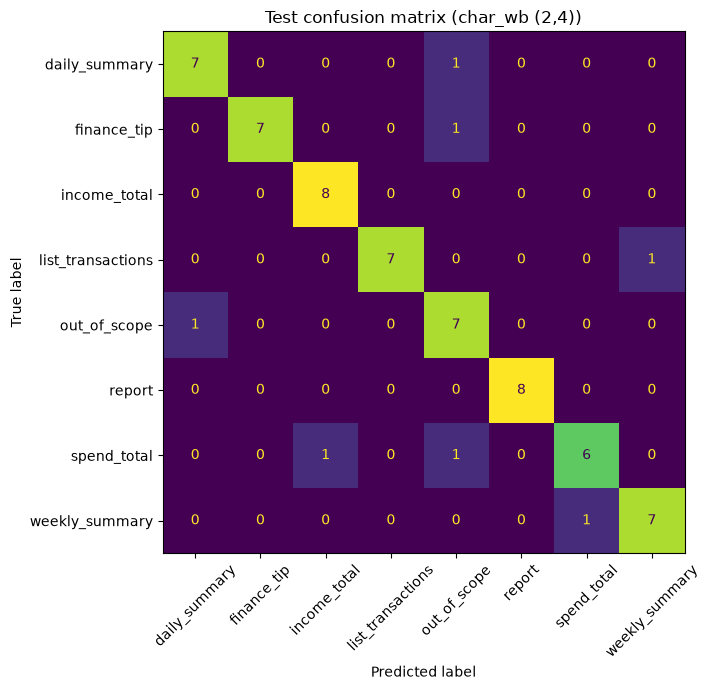

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title(f'Test confusion matrix ({best_name})')
plt.tight_layout()
plt.show()

In [7]:
# Read every mistake: this teaches more than the accuracy number
proba = model.predict_proba(X_test)
conf = proba.max(axis=1)
mistakes = test.assign(pred=pred, confidence=conf.round(2))[pred != y_test]
mistakes.sort_values('confidence', ascending=False)

,question,intent,pred,confidence
62,What day is it today?,out_of_scope,daily_summary,0.70
1,What's the damage for February so far,spend_total,out_of_scope,0.63
30,how bad was my spending these past 7 days,weekly_summary,spend_total,0.45
36,what did i pay for 2 weeks ago,list_transactions,weekly_summary,0.43
49,How do I make my salary last until the next pa...,finance_tip,out_of_scope,0.38
7,How much money left my wallet over the past 2 ...,spend_total,income_total,0.33
19,quick look at feb 14 spending,daily_summary,out_of_scope,0.32


## D. Pick `THRESHOLD`
Below the threshold the API returns `intent: null` and the app asks the user to rephrase.
Trade-off: higher threshold = fewer wrong answers, but more "I didn't get that".

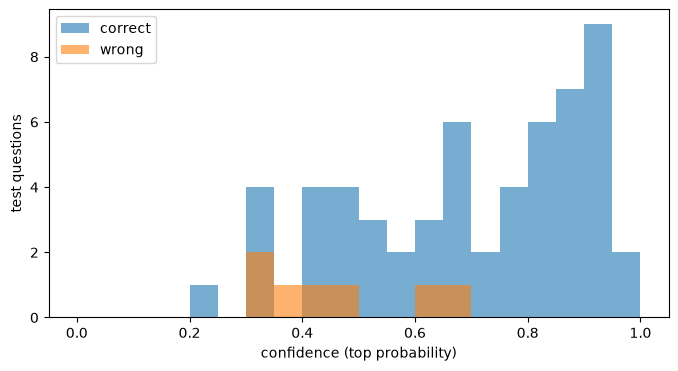

,threshold,answered,accuracy_when_answered,wrong_answers_shown
0,0.0,100%,0.891,7
1,0.2,100%,0.891,7
2,0.3,98%,0.889,7
3,0.4,88%,0.929,4
4,0.5,72%,0.957,2
5,0.6,64%,0.951,2
6,0.7,47%,1.000,0


In [8]:
correct = pred == y_test.values

plt.figure(figsize=(8, 4))
plt.hist(conf[correct], bins=20, range=(0, 1), alpha=0.6, label='correct')
plt.hist(conf[~correct], bins=20, range=(0, 1), alpha=0.6, label='wrong')
plt.xlabel('confidence (top probability)')
plt.ylabel('test questions')
plt.legend()
plt.show()

rows = []
for t in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    answered = conf >= t
    rows.append({
        'threshold': t,
        'answered': f'{answered.mean():.0%}',
        'accuracy_when_answered': round(correct[answered].mean(), 3) if answered.any() else None,
        'wrong_answers_shown': int((answered & ~correct).sum()),
    })
pd.DataFrame(rows)

In [9]:
THRESHOLD = 0.4  # change after reading the table above
print('wrong answers shown:', int(((conf >= THRESHOLD) & ~correct).sum()),
      '| questions refused:', int((conf < THRESHOLD).sum()))

wrong answers shown: 4 | questions refused: 8


## E. Try it on new questions

In [10]:
def ask(q):
    p = model.predict_proba([q.lower().strip()])[0]
    i = int(np.argmax(p))
    intent = model.classes_[i] if p[i] >= THRESHOLD else None
    return {'question': q, 'intent': intent, 'confidence': round(float(p[i]), 2)}

pd.DataFrame([ask(q) for q in [
    'how much did i spend from aug 4 to aug 11',
    'weekly summary',
    'all transactions report 10 years ago',
    'magkano kinita ko last month',
    'summry for today',
    'what is an emergency fund',
    'banana',
    'how much is a jollibee chickenjoy',
]])

,question,intent,confidence
0,how much did i spend from aug 4 to aug 11,spend_total,0.86
1,weekly summary,weekly_summary,0.99
2,all transactions report 10 years ago,report,0.91
3,magkano kinita ko last month,income_total,0.88
4,summry for today,daily_summary,0.96
5,what is an emergency fund,finance_tip,0.92
6,banana,out_of_scope,0.85
7,how much is a jollibee chickenjoy,NaN,0.29


## F. If a pair keeps getting confused
Add more **training** rows for that pair and re-run. Never edit `intents_test.csv` to make the score go up,
or the test stops measuring anything.

## G. Save for the API
Refit on train only (test stays unseen), then save next to `categorizer.joblib`.

In [11]:
from pathlib import Path

model.fit(X_train, y_train)
out = Path('../service/model/intents.joblib')
joblib.dump(model, out)
print(out, f'{out.stat().st_size / 1024:.0f} KB')

# Self-check: the saved file predicts the same as the model in memory
loaded = joblib.load(out)
assert (loaded.predict(X_test) == model.predict(X_test)).all()

..\service\model\intents.joblib 225 KB


## Takeaways (answer in your own words)

1. Why does `char_wb` help (or not) with typos like `summry` and `reprot`?
   - *Your answer:*
2. Why fix the training data instead of the test file?
   - *Your answer:*
3. What would the model do with "banana" if there were no `out_of_scope` class?
   - *Your answer:*
4. Which threshold did you pick, and what did you trade for it?
   - *Your answer:*